# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman implementasi Linear Regression dan Logistic Regression menggunakan NumPy, berdasarkan materi yang diberikan.

**Identitas Mahasiswa**
- Nama: Bryan Justin Valentino Derek
- NIM: 241011402659
- Kelas: Reg B
- Random state: 59

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# Import library yang diizinkan untuk pengerjaan utama
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 59
print("Random state:", RANDOM_STATE)

Random state: 59


In [2]:
# Implementasi train_test_split dari materi, tanpa scikit-learn.
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) != len(y):
        raise ValueError("X dan y harus memiliki jumlah baris yang sama.")
    if not 0 < test_size < 1:
        raise ValueError("test_size harus berada di antara 0 dan 1.")
    n_total = len(X)
    n_test = int(round(n_total * test_size))
    if n_test < 1 or n_test >= n_total:
        raise ValueError("Ukuran data testing tidak valid.")
    rng = np.random.RandomState(random_state) if random_state is not None else np.random
    indices = rng.permutation(n_total)
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

# Implementasi Linear Regression dengan Normal Equation.
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.pinv(X_b) @ y
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

# Implementasi Linear Regression dengan Gradient Descent.
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.converged_ = True
        self.iterations_run_ = 0

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])
        self.loss_history_ = []
        self.converged_ = True
        for iteration in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            with np.errstate(over="ignore", invalid="ignore"):
                beta = beta - self.learning_rate * gradient
                residual = y - X_b @ beta
                loss = np.mean(residual ** 2)
            self.iterations_run_ = iteration + 1
            if not np.all(np.isfinite(beta)) or not np.isfinite(loss):
                self.converged_ = False
                self.loss_history_.append(np.inf)
                break
            self.loss_history_.append(float(loss))
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

# Implementasi Logistic Regression dengan Gradient Descent.
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])
        self.loss_history_ = []
        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient
            p_new = np.clip(self._sigmoid(X_b @ beta), 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p_new) + (1-y) * np.log(1-p_new))
            self.loss_history_.append(float(loss))
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(1, -1) if len(self.coefficients_) > 1 else X.reshape(-1, 1)
        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Fungsi evaluasi untuk regresi dan klasifikasi.
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    mae = np.mean(np.abs(y_true-y_pred))
    mse = np.mean((y_true-y_pred)**2)
    rmse = np.sqrt(mse)
    denominator = np.sum((y_true-np.mean(y_true))**2)
    r2 = 1 - np.sum((y_true-y_pred)**2)/denominator if denominator != 0 else np.nan
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R²": r2}

def accuracy_score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_recall_f1(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    return precision, recall, f1

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


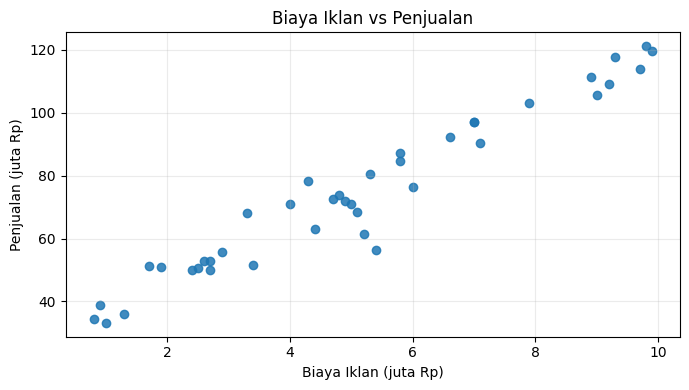

In [3]:
# Jawaban A1
ads_data = pd.read_csv("Ads_Data.csv")
display(ads_data.head())
print("Jumlah baris data:", len(ads_data))

X = ads_data[["BiayaIklan"]].to_numpy(dtype=float)
y = ads_data["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], y, alpha=0.85)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train_reg:", X_train_reg.shape)
print("X_test_reg :", X_test_reg.shape)
print("y_train_reg:", y_train_reg.shape)
print("y_test_reg :", y_test_reg.shape)

X_train_reg: (32, 1)
X_test_reg : (8, 1)
y_train_reg: (32,)
y_test_reg : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
regressor = LinearRegression().fit(X_train_reg, y_train_reg)
print(f"Intercept (b): {regressor.intercept_:.6f}")
print(f"Koefisien (m): {regressor.coefficients_[0]:.6f}")
print(f"Persamaan regresi: ŷ = {regressor.intercept_:.4f} + ({regressor.coefficients_[0]:.4f} × BiayaIklan)")

Intercept (b): 27.741367
Koefisien (m): 9.096725
Persamaan regresi: ŷ = 27.7414 + (9.0967 × BiayaIklan)


**Jawaban A3 (interpretasi):**

Koefisien model adalah sekitar **9,0967**, artinya pada garis regresi yang dipelajari, kenaikan biaya iklan sebesar Rp1 juta berkaitan dengan kenaikan prediksi penjualan sekitar **Rp9,10 juta**. Interpretasi ini menggambarkan hubungan pada dataset, bukan bukti bahwa biaya iklan menjadi satu-satunya penyebab perubahan penjualan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
y_train_pred_reg = regressor.predict(X_train_reg)
y_test_pred_reg = regressor.predict(X_test_reg)
metrics_table = pd.DataFrame(
    [regression_metrics(y_train_reg, y_train_pred_reg), regression_metrics(y_test_reg, y_test_pred_reg)],
    index=["Training", "Testing"]
)
display(metrics_table.round(4))

,MAE,MSE,RMSE,R²
Training,4.5471,37.6723,6.1378,0.9423
Testing,4.7274,30.9590,5.5641,0.9231


**Jawaban A4 (analisis):**

Pada data training, RMSE sebesar **6,1378 juta rupiah** dan R² sebesar **0,9423**. Pada data testing, RMSE sebesar **5,5641 juta rupiah** dan R² sebesar **0,9231**. Artinya, pada sampel testing model memiliki kesalahan prediksi sekitar 5,56 juta rupiah dalam ukuran RMSE dan menjelaskan sekitar 92,31% variasi target pada sampel tersebut. Hasil testing yang dekat dengan training menunjukkan kinerja yang cukup konsisten pada pembagian data ini, tetapi dataset hanya berisi 40 baris sehingga hasil tidak menjamin kinerja pada semua kondisi bisnis.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

,Learning rate,Iterasi dijalankan,Intercept,Koefisien,Loss terakhir,Status
0,0.001,5000,1.991993e+01,1.033753e+01,52.568697,finite setelah 5000 iterasi
1,0.020,5000,2.774137e+01,9.096725e+00,37.672289,finite setelah 5000 iterasi
2,0.100,462,-9.900852e+151,-6.241008e+152,inf,divergen (nilai tidak finite)


Normal Equation: b=27.741367, m=9.096725


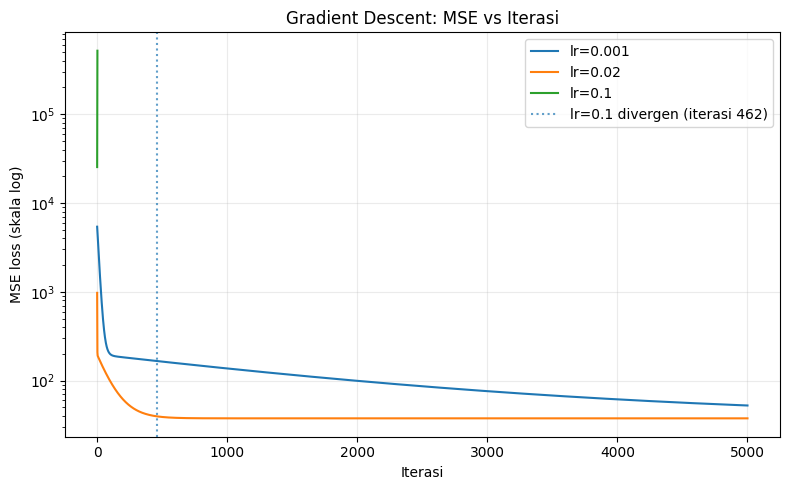

In [7]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
gd_rows = []
for lr in learning_rates:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train_reg, y_train_reg)
    gd_models[lr] = model
    gd_rows.append({
        "Learning rate": lr,
        "Iterasi dijalankan": model.iterations_run_,
        "Intercept": model.intercept_,
        "Koefisien": model.coefficients_[0],
        "Loss terakhir": model.loss_history_[-1],
        "Status": ("divergen (nilai tidak finite)" if not model.converged_ else "finite setelah 5000 iterasi")
    })
display(pd.DataFrame(gd_rows).round(6))
print(f"Normal Equation: b={regressor.intercept_:.6f}, m={regressor.coefficients_[0]:.6f}")

plt.figure(figsize=(8, 5))
for lr, model in gd_models.items():
    history = np.asarray(model.loss_history_, dtype=float)
    # Untuk grafik, batasi tampilan pada loss finite yang masih dapat dibaca;
    # tabel di atas tetap mencatat divergensi dan iterasi saat nilai tidak finite.
    visible = np.isfinite(history) & (history > 0) & (history <= 1e6)
    plt.plot(np.arange(1, len(history)+1)[visible], history[visible], label=f"lr={lr}")
    if not model.converged_:
        plt.axvline(model.iterations_run_, linestyle=":", alpha=0.7, label=f"lr={lr} divergen (iterasi {model.iterations_run_})")
plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("MSE loss (skala log)")
plt.title("Gradient Descent: MSE vs Iterasi")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

Pada eksperimen ini, learning rate **0,001** masih relatif lambat: setelah 5.000 iterasi, intercept sekitar 19,920, koefisien 10,338, dan MSE sekitar 52,569, sehingga belum mendekati solusi Normal Equation secara penuh. Learning rate **0,02** jauh lebih sesuai untuk data ini: setelah 5.000 iterasi, intercept sekitar 27,741, koefisien 9,097, dan MSE sekitar 37,672, sama dengan hasil Normal Equation pada presisi yang ditampilkan. Learning rate **0,1** terlalu besar dan divergen; parameter menjadi tidak finite pada iterasi ke-462. Hal ini terjadi karena langkah pembaruan terlalu besar untuk skala fitur dan target yang digunakan. Pada grafik, bagian loss yang sangat besar dibatasi agar kurva tetap terbaca; tabel mencatat status divergensi secara eksplisit.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

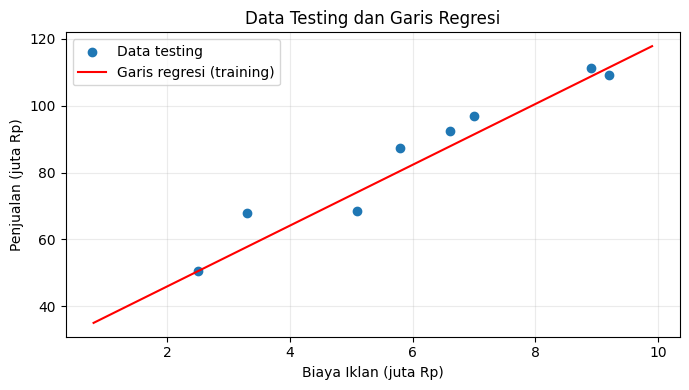

,BiayaIklan (juta Rp),Prediksi Penjualan (juta Rp)
0,4.5,68.677
1,7.0,91.418
2,12.0,136.902


In [8]:
# Jawaban A6
order = np.argsort(X_test_reg[:, 0])
plt.figure(figsize=(7, 4))
plt.scatter(X_test_reg[:, 0], y_test_reg, label="Data testing")
x_line = np.linspace(float(X.min()), float(X.max()), 200).reshape(-1, 1)
plt.plot(x_line[:, 0], regressor.predict(x_line), color="red", label="Garis regresi (training)")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = regressor.predict(biaya_baru)
prediksi_tabel = pd.DataFrame({
    "BiayaIklan (juta Rp)": biaya_baru[:, 0],
    "Prediksi Penjualan (juta Rp)": prediksi_penjualan
})
display(prediksi_tabel.round(3))

**Jawaban A6 (analisis):**

Prediksi pada 4,5 dan 7 juta lebih dapat dipertimbangkan jika nilainya berada dalam rentang biaya iklan yang tercakup oleh data. Prediksi pada 12 juta merupakan ekstrapolasi karena melampaui nilai maksimum dataset. Hubungan linear yang dipelajari dari rentang data yang terbatas belum tentu berlanjut di luar rentang tersebut, sehingga prediksi 12 juta perlu dianggap lebih tidak pasti dan tidak digunakan sebagai kepastian bisnis.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris data: 60
Jumlah kelas:


,Jumlah
Spam,
Bukan Spam,35
Spam,25


Shape X: (60, 2) | Shape y: (60,)


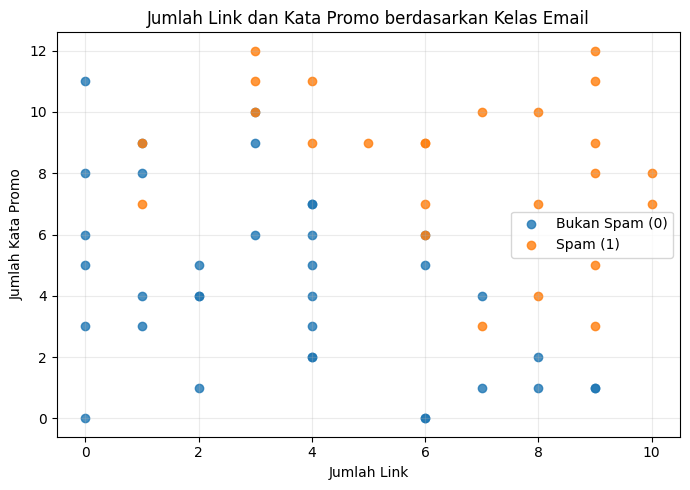

In [9]:
# Jawaban B1
email_data = pd.read_csv("Email_Data.csv")
display(email_data.head())
print("Jumlah baris data:", len(email_data))
print("Jumlah kelas:")
display(email_data["Spam"].map({0: "Bukan Spam", 1: "Spam"}).value_counts().rename("Jumlah").to_frame())

X_email = email_data[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email_data["Spam"].to_numpy(dtype=int)
print("Shape X:", X_email.shape, "| Shape y:", y_email.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], label="Bukan Spam (0)", alpha=0.8)
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], label="Spam (1)", alpha=0.8)
plt.title("Jumlah Link dan Kata Promo berdasarkan Kelas Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
y_train: (45,) | y_test: (15,)


Intercept (b): -11.567036
Koefisien (m1, m2): [1.0532435 0.9421543]
Persamaan: P(Spam) = sigmoid(-11.5670 + (1.0532 × JumlahLink) + (0.9422 × KataPromo))


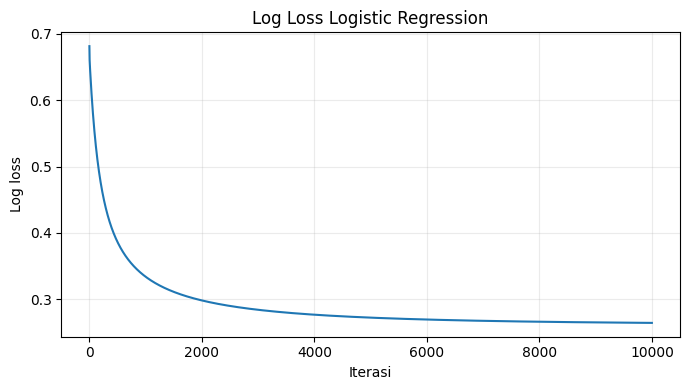

Log loss awal: 0.681384
Log loss akhir: 0.264458


In [10]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
print("X_train:", X_train_email.shape, "| X_test:", X_test_email.shape)
print("y_train:", y_train_email.shape, "| y_test:", y_test_email.shape)

classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(X_train_email, y_train_email)
print(f"Intercept (b): {classifier.intercept_:.6f}")
print(f"Koefisien (m1, m2): {classifier.coefficients_}")
print(
    "Persamaan: P(Spam) = sigmoid("
    f"{classifier.intercept_:.4f} + ({classifier.coefficients_[0]:.4f} × JumlahLink)"
    f" + ({classifier.coefficients_[1]:.4f} × KataPromo))"
)

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(classifier.loss_history_)+1), classifier.loss_history_)
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.title("Log Loss Logistic Regression")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Log loss awal: {classifier.loss_history_[0]:.6f}")
print(f"Log loss akhir: {classifier.loss_history_[-1]:.6f}")

**Jawaban B2 (analisis):**

Model mempelajari intercept **-11,5670** dan koefisien positif untuk jumlah link (**1,0532**) serta kata promo (**0,9422**). Dengan parameter ini, peningkatan nilai fitur menaikkan probabilitas spam menurut model, jika fitur lain tetap. Log loss turun dari sekitar **0,681384** pada awal pelatihan menjadi **0,264458** setelah 10.000 iterasi, sehingga model belajar membuat probabilitas yang lebih sesuai dengan label training. Evaluasi pada testing tetap diperlukan karena penurunan loss training saja tidak menjamin model bekerja baik pada data baru.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

Confusion matrix [[TN, FP], [FN, TP]]:
[[11  0]
 [ 1  3]]
Accuracy : 0.9333
Precision: 1.0000
Recall   : 0.7500
F1-score : 0.8571


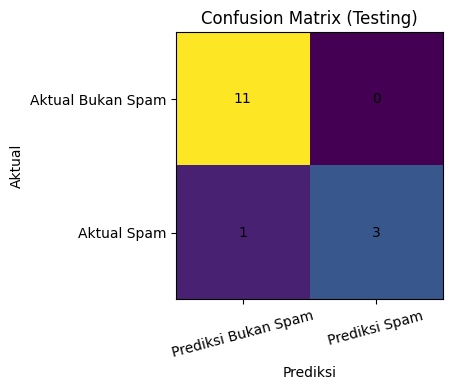

In [11]:
# Jawaban B3
y_test_pred = classifier.predict(X_test_email, threshold=0.5)
cm = confusion_matrix(y_test_email, y_test_pred)
precision, recall, f1 = precision_recall_f1(y_test_email, y_test_pred)
accuracy = accuracy_score(y_test_email, y_test_pred)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix (Testing)")
plt.xticks([0, 1], ["Prediksi Bukan Spam", "Prediksi Spam"], rotation=15)
plt.yticks([0, 1], ["Aktual Bukan Spam", "Aktual Spam"])
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha="center", va="center")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

**Jawaban B3 (analisis):**

Confusion matrix testing adalah `[[11, 0], [1, 3]]`: model benar mengklasifikasikan 11 email bukan spam dan 3 email spam, dengan **FP=0** dan **FN=1**. Accuracy adalah **93,33%**, precision **100%**, recall **75%**, dan F1-score **85,71%**. False Positive (FP) adalah email bukan spam yang keliru dimasukkan ke spam sehingga pengguna bisa melewatkan pesan penting. False Negative (FN) adalah email spam yang lolos ke kotak masuk. Dalam penggunaan email, FP dapat sangat merugikan karena pesan penting berisiko tersembunyi; karena itu precision dan recall perlu dipertimbangkan bersama.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: -11.567036 + (1.053244)*JumlahLink + (0.942154)*KataPromo = 0
KataPromo = -(-11.567036 + (1.053244)*JumlahLink) / (0.942154)
Salah klasifikasi: indeks test ke-13, fitur=[1, 7], aktual=1, prediksi=0


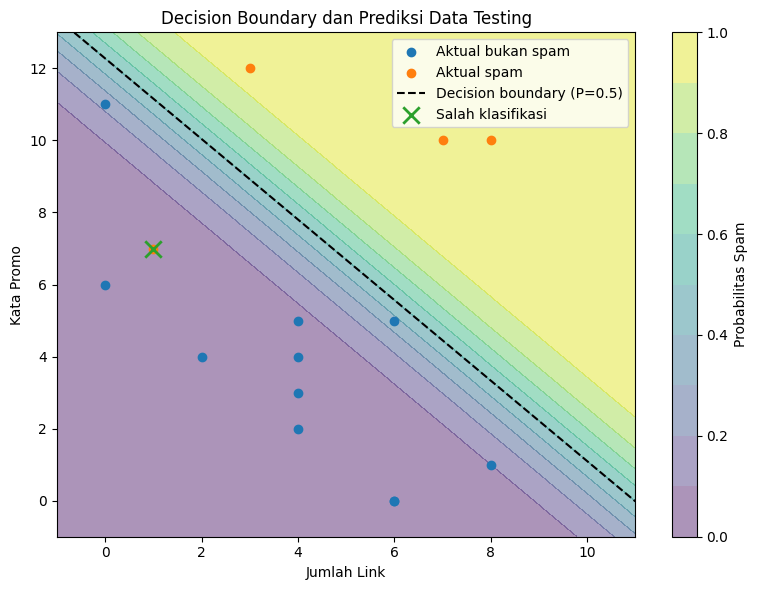

In [12]:
# Jawaban B4
b = classifier.intercept_
m1, m2 = classifier.coefficients_
print(f"Decision boundary: {b:.6f} + ({m1:.6f})*JumlahLink + ({m2:.6f})*KataPromo = 0")
if abs(m2) > 1e-12:
    print(f"KataPromo = -({b:.6f} + ({m1:.6f})*JumlahLink) / ({m2:.6f})")
else:
    print("Koefisien KataPromo mendekati nol; garis tidak dapat dinyatakan sebagai x2 = -(b+m1*x1)/m2.")

grid_x1, grid_x2 = np.meshgrid(
    np.linspace(X_email[:, 0].min()-1, X_email[:, 0].max()+1, 220),
    np.linspace(X_email[:, 1].min()-1, X_email[:, 1].max()+1, 220)
)
grid = np.c_[grid_x1.ravel(), grid_x2.ravel()]
grid_p = classifier.predict_proba(grid).reshape(grid_x1.shape)
plt.figure(figsize=(8, 6))
plt.contourf(grid_x1, grid_x2, grid_p, levels=np.linspace(0, 1, 11), alpha=0.45)
plt.colorbar(label="Probabilitas Spam")
plt.scatter(X_test_email[y_test_email == 0, 0], X_test_email[y_test_email == 0, 1], label="Aktual bukan spam")
plt.scatter(X_test_email[y_test_email == 1, 0], X_test_email[y_test_email == 1, 1], label="Aktual spam")
if abs(m2) > 1e-12:
    x1_line = np.linspace(grid_x1.min(), grid_x1.max(), 200)
    x2_line = -(b + m1*x1_line)/m2
    valid = (x2_line >= grid_x2.min()) & (x2_line <= grid_x2.max())
    plt.plot(x1_line[valid], x2_line[valid], color="black", linestyle="--", label="Decision boundary (P=0.5)")
wrong = y_test_pred != y_test_email
plt.scatter(X_test_email[wrong, 0], X_test_email[wrong, 1], marker="x", s=140, linewidths=2, label="Salah klasifikasi")
for idx in np.where(wrong)[0]:
    print(f"Salah klasifikasi: indeks test ke-{idx}, fitur={X_test_email[idx].astype(int).tolist()}, aktual={y_test_email[idx]}, prediksi={y_test_pred[idx]}")
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.title("Decision Boundary dan Prediksi Data Testing")
plt.legend()
plt.tight_layout()
plt.show()

**Jawaban B4 (analisis):**

Pada data testing terdapat **satu salah klasifikasi**, yaitu data dengan fitur `[JumlahLink=1, KataPromo=7]`: label aktualnya spam (1), tetapi diprediksi bukan spam (0). Titik ini ditandai silang pada grafik. Decision boundary menunjukkan batas probabilitas 0,5; kesalahan ini memperlihatkan bahwa dua fitur tersebut belum tentu cukup untuk memisahkan semua email spam dan bukan spam secara sempurna.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = (classifier.predict_proba(X_test_email) >= threshold).astype(int)
    threshold_predictions[threshold] = pred
    cm_t = confusion_matrix(y_test_email, pred)
    p_t, r_t, f1_t = precision_recall_f1(y_test_email, pred)
    tn, fp, fn, tp = cm_t.ravel()
    threshold_rows.append({
        "Threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Precision": p_t, "Recall": r_t, "F1-score": f1_t
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))

,Threshold,TN,FP,FN,TP,Precision,Recall,F1-score
0,0.3,10,1,1,3,0.75,0.75,0.7500
1,0.5,11,0,1,3,1.00,0.75,0.8571
2,0.7,11,0,1,3,1.00,0.75,0.8571


**Jawaban B5 (analisis):**

Pada data testing ini, threshold **0,3** menghasilkan TN=10, FP=1, FN=1, TP=3, precision=0,75 dan recall=0,75. Threshold **0,5** maupun **0,7** menghasilkan TN=11, FP=0, FN=1, TP=3, precision=1,00 dan recall=0,75. Jadi, menaikkan threshold dari 0,3 ke 0,5 menghilangkan satu false positive tanpa menambah false negative pada sampel testing ini; menaikkannya lagi ke 0,7 tidak mengubah hasil. Saya memilih threshold **0,5** sebagai kompromi sederhana: tidak ada email bukan spam yang salah masuk folder spam pada sampel testing, sementara recall tetap 0,75. Hasil ini berdasarkan sampel testing yang kecil sehingga perlu diuji pada lebih banyak email sebelum dipakai sebagai filter nyata.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
# Threshold pilihan: 0.5 sebagai titik kompromi awal; hasil threshold lain tersedia pada Soal B5.
THRESHOLD_PILIHAN = 0.5
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
X_baru = email_baru[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
email_baru["Probabilitas Spam"] = classifier.predict_proba(X_baru)
email_baru["Prediksi"] = np.where(
    email_baru["Probabilitas Spam"] >= THRESHOLD_PILIHAN, "Spam", "Bukan Spam"
)
email_baru["Threshold"] = THRESHOLD_PILIHAN
display(email_baru.round(4))

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi,Threshold
0,E1,1,2,0.0002,Bukan Spam,0.5
1,E2,5,6,0.3435,Bukan Spam,0.5
2,E3,9,10,0.9993,Spam,0.5
3,E4,2,11,0.7116,Spam,0.5


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression disebut regresi karena mempelajari kombinasi linear fitur, tetapi hasil akhirnya dipakai untuk menentukan kelas. Fungsi sigmoid mengubah nilai kombinasi linear menjadi probabilitas antara 0 dan 1. Probabilitas tersebut dibandingkan dengan threshold untuk menentukan kelas, misalnya spam atau bukan spam.

**Jawaban C2:** Normal Equation menghitung parameter regresi melalui satu perhitungan matriks, sehingga tidak membutuhkan proses iterasi. Gradient Descent memperbarui parameter berulang kali berdasarkan gradien loss dan learning rate. Gradient Descent berguna ketika jumlah fitur atau data besar sehingga perhitungan matriks langsung menjadi mahal, tetapi pemilihan learning rate dan jumlah iterasi perlu diperhatikan.

**Jawaban C3:** Data training dipakai untuk mempelajari parameter, sedangkan data testing dipakai untuk mengukur kinerja pada data yang tidak digunakan saat pelatihan. Jika evaluasi hanya dilakukan pada training, hasilnya bisa terlihat terlalu bagus. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training sehingga kinerjanya menurun pada data baru.

**Jawaban C4:** Linear Regression menghasilkan nilai kontinu dan MSE mengukur rata-rata kuadrat selisih prediksi dengan target numerik. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss mengukur seberapa baik probabilitas tersebut sesuai dengan label aktual. Log loss memberi penalti besar ketika model sangat yakin pada prediksi yang salah, sehingga cocok untuk pelatihan probabilistik klasifikasi.

**Jawaban C5:** Hasil dapat berbeda jika pembagian training-testing atau random state berbeda karena model dilatih dan dievaluasi pada subset data yang berbeda. Hasil juga dapat dipengaruhi oleh learning rate, jumlah iterasi, threshold, dan pengaturan model. Pada implementasi library, regularisasi dan metode optimasi juga dapat membuat koefisien berbeda walaupun datasetnya sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus: perbandingan dengan scikit-learn (hanya pada bagian bonus).
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import accuracy_score as sk_accuracy_score, confusion_matrix as sk_confusion_matrix
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Linear Regression sklearn menggunakan pembagian data training yang sama.
sk_reg = SklearnLinearRegression().fit(X_train_reg, y_train_reg)
sk_train_pred = sk_reg.predict(X_train_reg)
sk_test_pred = sk_reg.predict(X_test_reg)
bonus_linear = pd.DataFrame([
    {"Model": "Implementasi NumPy", "Intercept": regressor.intercept_,
     "Koefisien": regressor.coefficients_[0],
     "MAE testing": regression_metrics(y_test_reg, y_test_pred_reg)["MAE"],
     "MSE testing": regression_metrics(y_test_reg, y_test_pred_reg)["MSE"],
     "RMSE testing": regression_metrics(y_test_reg, y_test_pred_reg)["RMSE"],
     "R² testing": regression_metrics(y_test_reg, y_test_pred_reg)["R²"]},
    {"Model": "scikit-learn", "Intercept": sk_reg.intercept_,
     "Koefisien": sk_reg.coef_[0],
     "MAE testing": mean_absolute_error(y_test_reg, sk_test_pred),
     "MSE testing": mean_squared_error(y_test_reg, sk_test_pred),
     "RMSE testing": np.sqrt(mean_squared_error(y_test_reg, sk_test_pred)),
     "R² testing": r2_score(y_test_reg, sk_test_pred)}
])
print("Perbandingan Linear Regression:")
display(bonus_linear.round(6))

# scikit-learn Logistic Regression secara default memakai regularisasi L2.
# C besar mengurangi regularisasi agar perbandingan koefisien lebih sebanding.
sk_log = SklearnLogisticRegression(C=1e6, max_iter=10000, solver="lbfgs")
sk_log.fit(X_train_email, y_train_email)
sk_log_pred = sk_log.predict(X_test_email)
np_log_pred = classifier.predict(X_test_email, threshold=0.5)
bonus_logistic = pd.DataFrame([
    {"Model": "Implementasi NumPy", "Intercept": classifier.intercept_,
     "Koefisien JumlahLink": classifier.coefficients_[0],
     "Koefisien KataPromo": classifier.coefficients_[1],
     "Accuracy testing": accuracy_score(y_test_email, np_log_pred),
     "Precision testing": precision_recall_f1(y_test_email, np_log_pred)[0],
     "Recall testing": precision_recall_f1(y_test_email, np_log_pred)[1],
     "F1 testing": precision_recall_f1(y_test_email, np_log_pred)[2]},
    {"Model": "scikit-learn (C=1e6)", "Intercept": sk_log.intercept_[0],
     "Koefisien JumlahLink": sk_log.coef_[0, 0],
     "Koefisien KataPromo": sk_log.coef_[0, 1],
     "Accuracy testing": accuracy_score(y_test_email, sk_log_pred),
     "Precision testing": precision_recall_f1(y_test_email, sk_log_pred)[0],
     "Recall testing": precision_recall_f1(y_test_email, sk_log_pred)[1],
     "F1 testing": precision_recall_f1(y_test_email, sk_log_pred)[2]}
])
print("Perbandingan Logistic Regression:")
display(bonus_logistic.round(6))

Perbandingan Linear Regression:


,Model,Intercept,Koefisien,MAE testing,MSE testing,RMSE testing,R² testing
0,Implementasi NumPy,27.741367,9.096725,4.727423,30.958974,5.564079,0.92313
1,scikit-learn,27.741367,9.096725,4.727423,30.958974,5.564079,0.92313


Perbandingan Logistic Regression:


,Model,Intercept,Koefisien JumlahLink,Koefisien KataPromo,Accuracy testing,Precision testing,Recall testing,F1 testing
0,Implementasi NumPy,-11.567036,1.053244,0.942154,0.933333,1.0,0.75,0.857143
1,scikit-learn (C=1e6),-13.693860,1.254292,1.104027,0.933333,1.0,0.75,0.857143


**Jawaban Bonus (analisis):**

Pada Linear Regression, Normal Equation dengan pseudoinvers dan `sklearn.linear_model.LinearRegression` seharusnya menghasilkan parameter dan prediksi yang sangat dekat karena keduanya meminimalkan jumlah kuadrat error tanpa regularisasi. Perbedaan kecil dapat muncul karena presisi numerik.

Pada Logistic Regression, hasil dapat berbeda karena implementasi NumPy menggunakan Gradient Descent dengan learning rate dan jumlah iterasi tertentu, sedangkan scikit-learn menggunakan solver optimasi dan regularisasi. Parameter `C` mengatur kekuatan regularisasi secara terbalik; nilai `C` besar berarti regularisasi lebih lemah. Oleh karena itu, metrik testing dibandingkan dengan konfigurasi yang tercantum pada tabel, dan hasil tidak diasumsikan sama persis.